## This Notebook for Testing the library

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent

sys.path.insert(0, str(project_root))

In [2]:

# ============================================
# ZATML vs SCIKIT-LEARN
# Logistic Regression Benchmark
# ============================================

import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression as SKLogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Your library
from ZatML.Models.logisticRegression import LogisticRegression as ZatLogisticRegression
from ZatML.Utils.metric import Metrices


# ============================================
# CONFIGURATION
# ============================================

RANDOM_STATE = 42
TEST_SIZE = 0.2

ZAT_ITERATIONS = 2000
ZAT_LEARNING_RATE = 0.1

N_SPLITS = 5


# ============================================
# 1. LOAD DATASET
# ============================================

dataset = load_breast_cancer()

X = dataset.data

# 0 = Benign
# 1 = Malignant
y = (dataset.target == 0).astype(np.int64)

print("=" * 55)
print("DATASET INFORMATION")
print("=" * 55)

print("Dataset:", "Breast Cancer Wisconsin")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Benign:", np.sum(y == 0))
print("Malignant:", np.sum(y == 1))


# ============================================
# 2. METRICS FUNCTION
# ============================================

def calculate_metrics(y_true, y_pred):

    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }


def print_confusion_matrix(y_true, y_pred, model_name):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    print(f"\n{model_name} Confusion Matrix")
    print("                 Predicted")
    print("               Benign  Malignant")
    print(f"Actual Benign    {cm[0,0]:4d}    {cm[0,1]:4d}")
    print(f"Actual Malignant {cm[1,0]:4d}    {cm[1,1]:4d}")


def print_metrics(metrics, model_name):

    print(f"\n{model_name}")
    print("-" * 40)

    for metric, value in metrics.items():
        print(f"{metric:<15}: {value:.4f}")


# ============================================
# 3. TRAIN / TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)


# ============================================
# 4. FEATURE SCALING
# ============================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train_2d = y_train.reshape(-1, 1)


# ============================================
# 5. TRAIN ZATML
# ============================================

print("\n" + "=" * 55)
print("TRAINING ZATML")
print("=" * 55)

np.random.seed(RANDOM_STATE)

zat_model = ZatLogisticRegression(
    num_iter=ZAT_ITERATIONS,
    show_logs=False,
    lr=ZAT_LEARNING_RATE
)

zat_model.fit(X_train, y_train_2d)

zat_probabilities, zat_predictions = zat_model.predict(X_test)

zat_predictions = np.asarray(zat_predictions).reshape(-1)
zat_probabilities = np.asarray(zat_probabilities).reshape(-1)


# ============================================
# 6. TRAIN SCIKIT-LEARN
# ============================================

print("\n" + "=" * 55)
print("TRAINING SCIKIT-LEARN")
print("=" * 55)

sk_model = SKLogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=5000,
    tol=1e-10
)

sk_model.fit(X_train, y_train)

sk_predictions = sk_model.predict(X_test)

sk_probabilities = sk_model.predict_proba(X_test)[:, 1]


print("Scikit-learn iterations:", sk_model.n_iter_)


# ============================================
# 7. EVALUATE BOTH MODELS
# ============================================

zat_results = calculate_metrics(
    y_test,
    zat_predictions
)

sk_results = calculate_metrics(
    y_test,
    sk_predictions
)

print("\n" + "=" * 55)
print("FINAL TEST RESULTS")
print("=" * 55)

comparison = pd.DataFrame(
    [zat_results, sk_results],
    index=["ZATML", "Scikit-learn"]
)

print(comparison.round(4))


# ============================================
# 8. CONFUSION MATRICES
# ============================================

print_confusion_matrix(
    y_test,
    zat_predictions,
    "ZATML"
)

print_confusion_matrix(
    y_test,
    sk_predictions,
    "SCIKIT-LEARN"
)


# ============================================
# 9. CLASSIFICATION REPORT
# ============================================

print("\n" + "=" * 55)
print("ZATML CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        zat_predictions,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)

print("\n" + "=" * 55)
print("SCIKIT-LEARN CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        sk_predictions,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)


# ============================================
# 10. PREDICTION AGREEMENT
# ============================================

agreement = np.mean(
    zat_predictions == sk_predictions
)

disagreement = np.sum(
    zat_predictions != sk_predictions
)

print("\n" + "=" * 55)
print("PREDICTION COMPARISON")
print("=" * 55)

print(f"Agreement    : {agreement:.4f}")
print(f"Disagreement : {disagreement}")
print(f"Test Samples : {len(y_test)}")


# ============================================
# 11. ZATML METRICS IMPLEMENTATION TEST
# ============================================

print("\n" + "=" * 55)
print("TESTING YOUR ZATML METRICS")
print("=" * 55)

def evaluate_zatml_metrics(y_true, y_pred):

    # Create a new instance for each evaluation
    metric = Metrices()

    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    return {
        "Accuracy": metric.accuracy(y_pred, y_true),
        "Precision": metric.precesion(y_pred, y_true),
        "Recall": metric.recall(y_pred, y_true),
        "F1 Score": metric.f1_score(y_pred, y_true)
    }


for name, predictions in [
    ("ZATML predictions", zat_predictions),
    ("Scikit-learn predictions", sk_predictions)
]:

    print_metrics(
        evaluate_zatml_metrics(y_test, predictions),
        name + " - ZATML Metrics"
    )

    print_metrics(
        calculate_metrics(y_test, predictions),
        name + " - Reference Metrics"
    )


# ============================================
# 12. 5-FOLD CROSS VALIDATION
# ============================================

print("\n" + "=" * 55)
print("5-FOLD CROSS VALIDATION")
print("=" * 55)

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y), start=1
):

    print(f"\nRunning Fold {fold}/{N_SPLITS}")

    # Split raw data
    X_tr = X[train_idx]
    X_val = X[valid_idx]

    y_tr = y[train_idx]
    y_val = y[valid_idx]

    # Fit scaler only on the training fold
    fold_scaler = StandardScaler()

    X_tr = fold_scaler.fit_transform(X_tr)
    X_val = fold_scaler.transform(X_val)

    # ----------------------------------------
    # ZATML
    # ----------------------------------------

    np.random.seed(RANDOM_STATE + fold)

    fold_zat_model = ZatLogisticRegression(
        num_iter=ZAT_ITERATIONS,
        show_logs=False,
        lr=ZAT_LEARNING_RATE
    )

    fold_zat_model.fit(
        X_tr,
        y_tr.reshape(-1, 1)
    )

    _, fold_zat_predictions = fold_zat_model.predict(X_val)

    fold_zat_predictions = np.asarray(
        fold_zat_predictions
    ).reshape(-1)

    zat_fold_metrics = calculate_metrics(
        y_val,
        fold_zat_predictions
    )

    cv_results.append({
        "Fold": fold,
        "Model": "ZATML",
        **zat_fold_metrics
    })

    # ----------------------------------------
    # SCIKIT-LEARN
    # ----------------------------------------

    fold_sk_model = SKLogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=5000,
        tol=1e-10
    )

    fold_sk_model.fit(X_tr, y_tr)

    fold_sk_predictions = fold_sk_model.predict(X_val)

    sk_fold_metrics = calculate_metrics(
        y_val,
        fold_sk_predictions
    )

    cv_results.append({
        "Fold": fold,
        "Model": "Scikit-learn",
        **sk_fold_metrics
    })


# ============================================
# 13. CROSS VALIDATION RESULTS
# ============================================

cv_df = pd.DataFrame(cv_results)

print("\nIndividual Fold Results:")
print(cv_df.round(4).to_string(index=False))

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

cv_summary = cv_df.groupby("Model")[metric_columns].agg(
    ["mean", "std"]
)

print("\n" + "=" * 55)
print("CROSS VALIDATION SUMMARY")
print("=" * 55)

print(cv_summary.round(4))


# ============================================
# 14. FINAL INTERPRETATION
# ============================================

print("\n" + "=" * 55)
print("BENCHMARK COMPLETED")
print("=" * 55)

print("Holdout comparison:")
print(comparison.round(4))

print("\nCross-validation mean F1 scores:")

print(
    cv_summary["F1 Score"]["mean"].sort_values(
        ascending=False
    )
)


DATASET INFORMATION
Dataset: Breast Cancer Wisconsin
Samples: 569
Features: 30
Benign: 357
Malignant: 212

TRAINING ZATML

TRAINING SCIKIT-LEARN
Scikit-learn iterations: [57]

FINAL TEST RESULTS
              Accuracy  Precision  Recall  F1 Score
ZATML           0.9737     0.9756  0.9524    0.9639
Scikit-learn    0.9386     0.9487  0.8810    0.9136

ZATML Confusion Matrix
                 Predicted
               Benign  Malignant
Actual Benign      71       1
Actual Malignant    2      40

SCIKIT-LEARN Confusion Matrix
                 Predicted
               Benign  Malignant
Actual Benign      70       2
Actual Malignant    5      37

ZATML CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

DATASET INFORMATION
Dataset: Diabetes
Samples: 442
Features: 10
Target Range: 25.0 - 346.0
Feature Names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

TRAINING ZATML LINEAR REGRESSION

TRAINING SCIKIT-LEARN LINEAR REGRESSION

HOLDOUT TEST RESULTS
                  MAE        MSE     RMSE      R2
ZATML         42.7941  2900.1905  53.8534  0.4526
Scikit-learn  42.7941  2900.1936  53.8534  0.4526

PREDICTION COMPARISON
Mean Absolute Prediction Difference: 0.0003428910426634957
Prediction Correlation: 0.9999999999716818

First 10 Predictions:
   Actual   ZATML  Scikit-learn
0   219.0  139.55        139.55
1    70.0  179.52        179.52
2   202.0  134.04        134.04
3   230.0  291.42        291.42
4   111.0  123.79        123.79
5    84.0   92.17         92.17
6   242.0  258.23        258.23
7   272.0  181.34        181.34
8    94.0   90.22         90.22
9    96.0  108.63        108.63

5-FOLD CROSS VALIDATION

Running Fold 1/5
[10000|1]==============================>

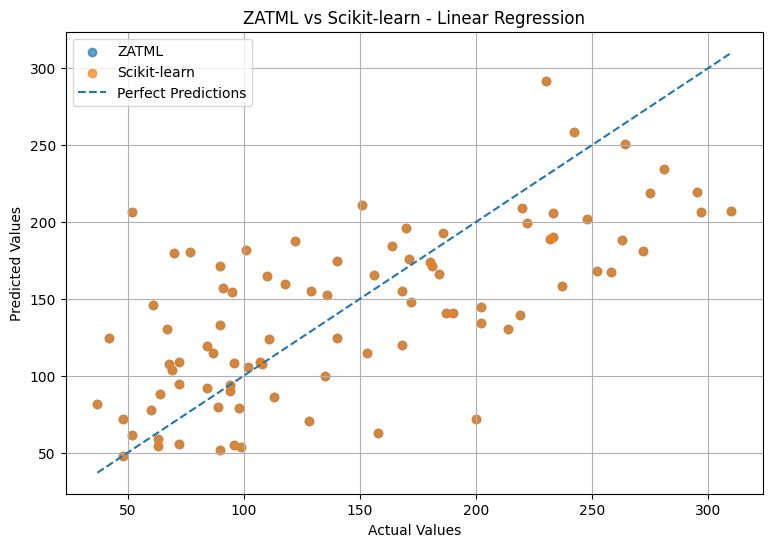


BENCHMARK COMPLETED

HOLDOUT:
                  MAE        MSE     RMSE      R2
ZATML         42.7941  2900.1905  53.8534  0.4526
Scikit-learn  42.7941  2900.1936  53.8534  0.4526

CROSS VALIDATION MEAN:
                  MAE        MSE     RMSE      R2
Model                                            
Scikit-learn  45.0482  3074.1421  55.3946  0.4804
ZATML         45.0481  3074.1390  55.3946  0.4804


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression as SKLinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from ZatML.Models.linearRegression import (
    LinearRegression as ZatLinearRegression
)


# ============================================
# CONFIGURATION
# ============================================

RANDOM_STATE = 42
TEST_SIZE = 0.2

NUM_ITER = 10_000
LR = 0.05

N_SPLITS = 5


# ============================================
# 1. LOAD REAL DATASET
# ============================================

dataset = load_diabetes()

X = dataset.data
y = dataset.target

print("=" * 55)
print("DATASET INFORMATION")
print("=" * 55)

print("Dataset: Diabetes")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Target Range:", y.min(), "-", y.max())

print("Feature Names:")
print(dataset.feature_names)


# ============================================
# 2. HELPER FUNCTIONS
# ============================================

def get_predictions(model, X):

    output = model.predict(X)

    # Support models that return a tuple
    if isinstance(output, tuple):
        output = output[0]

    return np.asarray(
        output,
        dtype=np.float64
    ).reshape(-1)


def calculate_regression_metrics(y_true, y_pred):

    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    mse = mean_squared_error(y_true, y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }


# ============================================
# 3. TRAIN / TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)


# ============================================
# 4. FEATURE SCALING
# ============================================

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Scale target for stable gradient descent
y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
)


# ============================================
# 5. TRAIN ZATML LINEAR REGRESSION
# ============================================

print("\n" + "=" * 55)
print("TRAINING ZATML LINEAR REGRESSION")
print("=" * 55)

np.random.seed(RANDOM_STATE)

zatlinear = ZatLinearRegression(
    num_iter=NUM_ITER,
    lr=LR,
    show_logs=False
)

zatlinear.fit(
    X_train_scaled,
    y_train_scaled
)

zat_pred_scaled = get_predictions(
    zatlinear,
    X_test_scaled
)

# Return predictions to original target scale
zat_predictions = y_scaler.inverse_transform(
    zat_pred_scaled.reshape(-1, 1)
).ravel()


# ============================================
# 6. TRAIN SCIKIT-LEARN
# ============================================

print("\n" + "=" * 55)
print("TRAINING SCIKIT-LEARN LINEAR REGRESSION")
print("=" * 55)

sk_model = SKLinearRegression(
    fit_intercept=True
)

sk_model.fit(
    X_train_scaled,
    y_train_scaled.ravel()
)

sk_pred_scaled = sk_model.predict(
    X_test_scaled
)

sk_predictions = y_scaler.inverse_transform(
    sk_pred_scaled.reshape(-1, 1)
).ravel()


# ============================================
# 7. HOLDOUT EVALUATION
# ============================================

zat_results = calculate_regression_metrics(
    y_test,
    zat_predictions
)

sk_results = calculate_regression_metrics(
    y_test,
    sk_predictions
)

comparison = pd.DataFrame(
    [zat_results, sk_results],
    index=["ZATML", "Scikit-learn"]
)

print("\n" + "=" * 55)
print("HOLDOUT TEST RESULTS")
print("=" * 55)

print(comparison.round(4))


# ============================================
# 8. PREDICTION COMPARISON
# ============================================

print("\n" + "=" * 55)
print("PREDICTION COMPARISON")
print("=" * 55)

print(
    "Mean Absolute Prediction Difference:",
    np.mean(np.abs(zat_predictions - sk_predictions))
)

print(
    "Prediction Correlation:",
    np.corrcoef(zat_predictions, sk_predictions)[0, 1]
)

predictions_df = pd.DataFrame({
    "Actual": y_test,
    "ZATML": zat_predictions,
    "Scikit-learn": sk_predictions
})

print("\nFirst 10 Predictions:")
print(predictions_df.head(10).round(2))


# ============================================
# 9. 5-FOLD CROSS VALIDATION
#    Only on training data
# ============================================

print("\n" + "=" * 55)
print("5-FOLD CROSS VALIDATION")
print("=" * 55)

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train), start=1
):

    print(f"\nRunning Fold {fold}/{N_SPLITS}")

    X_fold_train = X_train[train_idx]
    X_fold_val = X_train[val_idx]

    y_fold_train = y_train[train_idx]
    y_fold_val = y_train[val_idx]

    # ----------------------------------------
    # Scaling
    # ----------------------------------------

    fold_x_scaler = StandardScaler()
    fold_y_scaler = StandardScaler()

    X_fold_train_scaled = fold_x_scaler.fit_transform(
        X_fold_train
    )

    X_fold_val_scaled = fold_x_scaler.transform(
        X_fold_val
    )

    y_fold_train_scaled = fold_y_scaler.fit_transform(
        y_fold_train.reshape(-1, 1)
    )

    # ----------------------------------------
    # ZATML
    # ----------------------------------------

    np.random.seed(RANDOM_STATE + fold)

    fold_zat = ZatLinearRegression(
        num_iter=NUM_ITER,
        lr=LR
    )

    fold_zat.fit(
        X_fold_train_scaled,
        y_fold_train_scaled
    )

    zat_fold_scaled = get_predictions(
        fold_zat,
        X_fold_val_scaled
    )

    zat_fold_pred = fold_y_scaler.inverse_transform(
        zat_fold_scaled.reshape(-1, 1)
    ).ravel()

    zat_metrics = calculate_regression_metrics(
        y_fold_val,
        zat_fold_pred
    )

    cv_results.append({
        "Fold": fold,
        "Model": "ZATML",
        **zat_metrics
    })

    # ----------------------------------------
    # SCIKIT-LEARN
    # ----------------------------------------

    fold_sk = SKLinearRegression(
        fit_intercept=True
    )

    fold_sk.fit(
        X_fold_train_scaled,
        y_fold_train_scaled.ravel()
    )

    sk_fold_scaled = fold_sk.predict(
        X_fold_val_scaled
    )

    sk_fold_pred = fold_y_scaler.inverse_transform(
        sk_fold_scaled.reshape(-1, 1)
    ).ravel()

    sk_metrics = calculate_regression_metrics(
        y_fold_val,
        sk_fold_pred
    )

    cv_results.append({
        "Fold": fold,
        "Model": "Scikit-learn",
        **sk_metrics
    })


# ============================================
# 10. CROSS VALIDATION SUMMARY
# ============================================

cv_df = pd.DataFrame(cv_results)

print("\nIndividual Fold Results:")
print(cv_df.round(4).to_string(index=False))

metric_columns = [
    "MAE",
    "MSE",
    "RMSE",
    "R2"
]

cv_summary = cv_df.groupby("Model")[
    metric_columns
].agg(["mean", "std"])

print("\n" + "=" * 55)
print("CROSS VALIDATION SUMMARY")
print("=" * 55)

print(cv_summary.round(4))


# ============================================
# 11. VISUALIZATION
# ============================================

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    zat_predictions,
    label="ZATML",
    alpha=0.7
)

plt.scatter(
    y_test,
    sk_predictions,
    label="Scikit-learn",
    alpha=0.7
)

lower = min(
    y_test.min(),
    zat_predictions.min(),
    sk_predictions.min()
)

upper = max(
    y_test.max(),
    zat_predictions.max(),
    sk_predictions.max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    label="Perfect Predictions"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("ZATML vs Scikit-learn - Linear Regression")

plt.legend()
plt.grid(True)
plt.show()


# ============================================
# 12. FINAL SUMMARY
# ============================================

print("\n" + "=" * 55)
print("BENCHMARK COMPLETED")
print("=" * 55)

print("\nHOLDOUT:")
print(comparison.round(4))

print("\nCROSS VALIDATION MEAN:")
print(cv_summary.xs("mean", axis=1, level=1).round(4))


In [4]:
# Compare learned weights
zat_weights = np.asarray(zatlinear.w).reshape(-1)
sk_weights = np.asarray(sk_model.coef_).reshape(-1)

print(
    "Max Weight Difference:",
    np.max(np.abs(zat_weights - sk_weights))
)

print(
    "Weight Difference Norm:",
    np.linalg.norm(zat_weights - sk_weights)
)


# Compare bias
zat_bias = float(np.asarray(zatlinear.b).squeeze())
sk_bias = float(np.asarray(sk_model.intercept_).squeeze())

print("ZATML Bias:", zat_bias)
print("Sklearn Bias:", sk_bias)

print(
    "Bias Difference:",
    abs(zat_bias - sk_bias)
)

Max Weight Difference: 4.8661328850840846e-05
Weight Difference Norm: 6.835337893351858e-05
ZATML Bias: -2.375581278367926e-16
Sklearn Bias: -2.0449292404793318e-16
Bias Difference: 3.30652037888594e-17
